# 04 · Results: what the data show

**Purpose.** Draw the three descriptive figures, build the table of annual minima and fit the annual daytime low on PV capacity and on the year, and show the numbers behind each.

**Paper section served.** IV-A Results: what the data show.

**Inputs**

- `data/interim/network_30min.parquet` from notebook 01.
- `data/interim/pv_annual.parquet` and `weather_daily.parquet` from notebook 02.

**Paper artifacts**

- `outputs/figures/fig2`, `fig3`, `fig4` (each as PNG at 600 dpi and PDF): Fig. 2, Fig. 3 and Fig. 4.
- `outputs/tables/table2.csv`: Table II, each year's minimum, the day it fell on, and the year's two lows.
- `outputs/tables/table_pv_fit.csv`: straight-line fit of the annual daytime low on PV capacity and on the year.
- `outputs/tables/fig2_data.csv` and `fig4_fits.csv`: the values behind Fig. 2 and the lines in Fig. 4.

**Supporting checks** (`outputs/checks`)

- `check_trough_windows.csv`: how often the day's minimum falls outside both trough windows.

**Main process**

1. Set up.
2. Fig. 2: when the lowest half hours occur.
3. Fig. 3: the low end of the load duration curve.
4. Table II: each year's minimum.
5. Fig. 4: the daytime low against sunshine, and the daily minimum against temperature.
6. The annual daytime low against PV capacity and against the year.
7. Check: do the two trough windows catch the daily minimum?
8. Result.

## 1. Set up

In [1]:
import pandas as pd

from pynmdf import plots, targets
from pynmdf.config import load_config

cfg = load_config()
interim, figures, tables, checks = (
    cfg["dirs"][key] for key in ("interim", "figures", "tables", "checks")
)
windows = cfg["targets"]["troughs"]
selected_years = cfg["figures"]["selected_years"]
plots.set_style()

pd.set_option("display.width", 220, "display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)
total = pd.read_parquet(interim / "network_30min.parquet")["total_mw"]
weather = pd.read_parquet(interim / "weather_daily.parquet")
capacity = pd.read_parquet(interim / "pv_annual.parquet")["kwp"]

## 2. Fig. 2: when the lowest half hours occur

Take the lowest 1% of each year's valid half hours (about 175 of them) and count how many start in each clock hour. The heat map shows that share by year and hour; the bars beneath show PV capacity at 30 June. Times are local clock time, so the midday trough sits about an hour later on the clock in daylight-saving months.

The table is the figure's data: each column sums to 100.

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
year,,,,,,,,,,,,,,,,,,,,,,,,
2015,0,0,1,24,48,27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2016,0,0,0,27,46,23,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2017,0,0,1,25,49,22,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2018,0,0,0,26,49,21,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2019,0,0,0,27,49,22,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2020,0,0,1,23,46,28,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2021,0,0,0,17,43,19,2,0,0,0,4,5,3,3,3,2,0,0,0,0,0,0,0,0
2022,0,0,4,21,29,16,2,1,0,1,2,5,5,8,5,1,0,0,0,0,0,0,0,0
2023,0,0,0,0,0,0,0,1,2,5,13,22,22,21,12,2,0,0,0,0,0,0,0,0


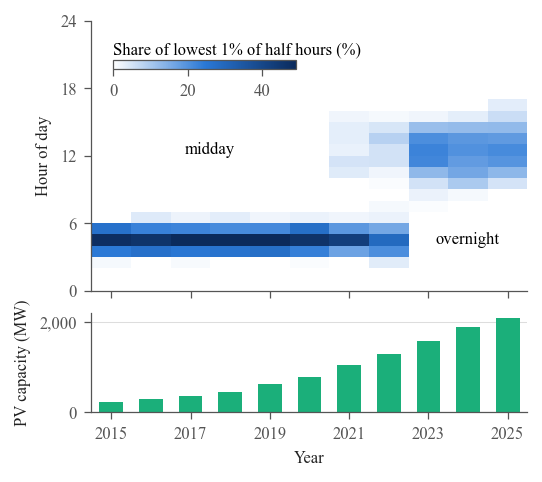

In [2]:
lowest = targets.lowest_intervals(total, cfg["figures"]["low_share"])
hour_shares = targets.low_hour_shares(lowest)
hour_shares.to_csv(tables / "fig2_data.csv")

figure = plots.fig2_low_hours(hour_shares, capacity)
plots.save_figure(figure, figures, "fig2")
hour_shares.round().astype(int).T

## 3. Fig. 3: the low end of the load duration curve

The same lowest 1% of half hours, sorted from the lowest, for three years. The marker at the left end is the year's absolute minimum.

The table gives the two ends of each curve.

year,2015,2020,2025
minimum_mw,"1,368.1","1,429.5",880.1
at_1pct_mw,"1,464.7","1,522.9","1,236.3"


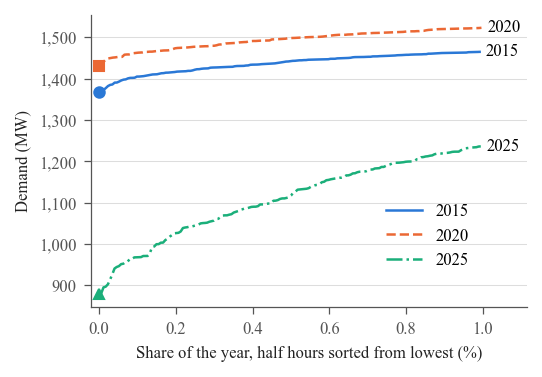

In [3]:
figure = plots.fig3_low_duration(lowest, selected_years)
plots.save_figure(figure, figures, "fig3")

curves = lowest[lowest["year"].isin(selected_years)].groupby("year")["mw"]
pd.DataFrame({"minimum_mw": curves.min(), "at_1pct_mw": curves.max()}).T

## 4. Table II: each year's minimum

For each year: the minimum, the date, the time its half hour ended, the day of the week, the public holiday if it was one, and that day's solar exposure and maximum temperature at Sydney Airport. The last two columns give the year's overnight low (00:00 to 06:00) and daytime low (09:00 to 17:00); the minimum is the lower of the two.

In [4]:
table2 = targets.annual_minimum_table(
    total, weather, cfg["calendar"]["holiday_subdivision"], windows
)
table2.to_csv(tables / "table2.csv")
table2

,min_mw,date,time,day,public_holiday,solar_mj_m2,tmax_c,overnight_low_mw,daytime_low_mw
year,,,,,,,,,
2015,"1,368.1",2015-04-05,04:30,Sun,Easter Sunday,16.2,23.2,"1,368.1","1,832.6"
2016,"1,432.6",2016-04-24,05:00,Sun,,14.3,22.0,"1,432.6","1,891.4"
2017,"1,474.3",2017-04-17,04:30,Mon,Easter Monday,14.2,23.7,"1,474.3","1,888.2"
2018,"1,495.1",2018-04-29,05:00,Sun,,13.4,20.2,"1,495.1","1,901.7"
2019,"1,473.0",2019-11-10,05:00,Sun,,28.6,23.9,"1,473.0","1,759.2"
2020,"1,429.5",2020-04-12,05:00,Sun,Easter Sunday,17.1,20.5,"1,429.5","1,671.0"
2021,"1,357.4",2021-10-17,14:30,Sun,,25.7,21.5,"1,387.6","1,357.4"
2022,"1,428.3",2022-04-17,05:00,Sun,Easter Sunday,14.9,24.7,"1,428.3","1,457.9"
2023,"1,080.0",2023-10-29,13:00,Sun,,27.4,26.0,"1,393.2","1,080.0"


## 5. Fig. 4: sunshine and temperature

Each point is one day, for three years. Sunshine acts on the midday dip, so the left panel plots the day's **daytime low** against that day's solar exposure, with a least-squares line per year. Temperature acts on the whole day, so the right panel plots the day's **minimum** against its mean temperature. Only days on which both trough windows are complete are used.

The table gives the left panel's lines, so the slopes can be quoted. A slope is in MW per MJ/m².

year,2015,2020,2025
slope,0.6,-6.6,-35.4
intercept,"2,578.7","2,477.0","2,540.8"
x_min,2.7,1.3,2.6
x_max,33.1,31.7,31.9
days,358.0,347.0,360.0


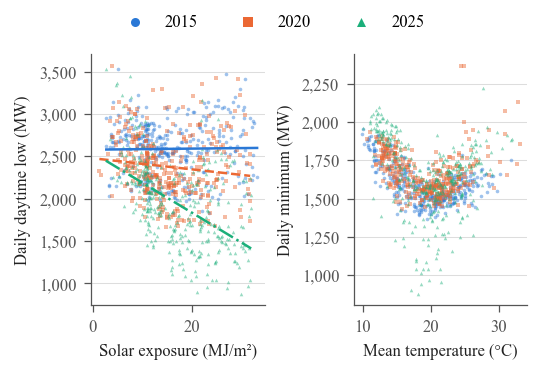

In [5]:
daily = pd.concat(
    [
        targets.daily_minimum(total),
        targets.daily_troughs(total, windows)["daytime"],
        weather[["solar", "tmean"]],
    ],
    axis=1,
    join="inner",
)
solar_fits = targets.yearly_line_fits(daily, "solar", "daytime", selected_years)
solar_fits.to_csv(tables / "fig4_fits.csv")

figure = plots.fig4_weather(daily, solar_fits)
plots.save_figure(figure, figures, "fig4")
solar_fits.T

## 6. The annual daytime low against PV capacity and against the year

Two straight lines are fitted to the eleven annual daytime lows of 2015 to 2025: one on PV capacity, one on the year. PV capacity is the published network total at 30 June of each year, in MW. Each line is fitted on its own, so the two can be compared: which single quantity tracks the daytime low more closely over the decade.

The first table is the data. The second gives each line's slope (MW of daytime low per MW of PV capacity, or per year), its intercept, R-squared and RMSE. RMSE is the root mean squared residual of the eleven points, in MW, with no adjustment for the two fitted parameters.

In [6]:
annual_lows = targets.annual_window_lows(total, windows)
fitted_on = pd.DataFrame(
    {
        "daytime_low_mw": annual_lows["daytime_low_mw"],
        "pv_mw": capacity / 1000,
        "year": annual_lows.index,
    }
)
pv_fit = targets.line_fits(fitted_on, "daytime_low_mw", ["pv_mw", "year"])
pv_fit.to_csv(tables / "table_pv_fit.csv")
fitted_on[["daytime_low_mw", "pv_mw"]].T.round()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
daytime_low_mw,"1,833.0","1,891.0","1,888.0","1,902.0","1,759.0","1,671.0","1,357.0","1,458.0","1,080.0","1,019.0",880.0
pv_mw,230.0,287.0,346.0,449.0,620.0,780.0,"1,050.0","1,291.0","1,563.0","1,882.0","2,084.0"


In [7]:
print(pv_fit.to_string(float_format="{:,.3f}".format))

             slope   intercept  r_squared    rmse  points
fitted_on                                                
pv_mw       -0.570   2,070.131      0.958  75.080      11
year      -108.773 221,243.283      0.879 127.776      11


## 7. Check: do the two trough windows catch the daily minimum?

The daily models fit an overnight trough (00:00 to 06:00) and a daytime trough (09:00 to 17:00) separately and take the lower. That only works if the day's true minimum falls inside one of the two windows. This check counts the days on which it does not, and shows how often the daytime trough is the lower one.

In [8]:
troughs = targets.daily_troughs(total, windows)
both = pd.concat([targets.daily_minimum(total), troughs], axis=1).dropna()
lower_trough = both[["overnight", "daytime"]].min(axis=1)
miss = lower_trough - both["min_mw"]  # how far the true minimum sits below both troughs
year = both.index.year

window_check = pd.DataFrame(
    {
        "complete_days": both.groupby(year).size(),
        "minimum_outside_both_pct": 100 * (miss > 1e-9).groupby(year).mean(),
        "largest_miss_mw": miss.groupby(year).max(),
        "daytime_lower_pct": 100 * (both["daytime"] < both["overnight"]).groupby(year).mean(),
    }
).rename_axis("year")
window_check.to_csv(checks / "check_trough_windows.csv")
window_check.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
complete_days,357.0,361.0,360.0,365.0,353.0,347.0,331.0,352.0,342.0,309.0,359.0
minimum_outside_both_pct,0.0,0.3,0.6,0.0,0.0,0.0,0.0,0.0,0.3,0.3,0.3
largest_miss_mw,0.0,398.7,40.4,0.0,0.0,0.0,0.0,0.0,0.4,31.9,14.2
daytime_lower_pct,0.0,0.0,0.0,0.0,0.0,0.0,0.9,3.4,17.8,26.2,32.9


## 8. Result

The numbers behind the items of this notebook, in one place.

In [9]:
midday = hour_shares.loc[9:16].sum()
print("Share of each year's lowest 1% of half hours starting between 09:00 and 17:00 (%):")
print(midday.round().astype(int).to_dict())
print()
print("Slope of the daily daytime low on solar exposure (MW per MJ/m2):")
print(solar_fits["slope"].round(1).to_dict())
print()
print("Annual daytime low fitted on PV capacity and on the year (R-squared; RMSE in MW):")
print(pv_fit[["r_squared", "rmse"]].round({"r_squared": 3, "rmse": 1}).T.to_dict())
print()
worst = window_check["minimum_outside_both_pct"].max()
print(f"Days whose minimum falls outside both trough windows: {worst:.1f}% at most in any year")
table2[["min_mw", "date", "time", "day", "overnight_low_mw", "daytime_low_mw"]]

Share of each year's lowest 1% of half hours starting between 09:00 and 17:00 (%):


{2015: 0, 2016: 0, 2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 19, 2022: 27, 2023: 97, 2024: 99, 2025: 100}

Slope of the daily daytime low on solar exposure (MW per MJ/m2):
{2015: 0.6, 2020: -6.6, 2025: -35.4}

Annual daytime low fitted on PV capacity and on the year (R-squared; RMSE in MW):
{'pv_mw': {'r_squared': 0.958, 'rmse': 75.1}, 'year': {'r_squared': 0.879, 'rmse': 127.8}}

Days whose minimum falls outside both trough windows: 0.6% at most in any year


,min_mw,date,time,day,overnight_low_mw,daytime_low_mw
year,,,,,,
2015,"1,368.1",2015-04-05,04:30,Sun,"1,368.1","1,832.6"
2016,"1,432.6",2016-04-24,05:00,Sun,"1,432.6","1,891.4"
2017,"1,474.3",2017-04-17,04:30,Mon,"1,474.3","1,888.2"
2018,"1,495.1",2018-04-29,05:00,Sun,"1,495.1","1,901.7"
2019,"1,473.0",2019-11-10,05:00,Sun,"1,473.0","1,759.2"
2020,"1,429.5",2020-04-12,05:00,Sun,"1,429.5","1,671.0"
2021,"1,357.4",2021-10-17,14:30,Sun,"1,387.6","1,357.4"
2022,"1,428.3",2022-04-17,05:00,Sun,"1,428.3","1,457.9"
2023,"1,080.0",2023-10-29,13:00,Sun,"1,393.2","1,080.0"
